# 04 · Graded Architectural Relevance

### From exact style labels to architectural similarity

---

## Notebook objective

Conventional retrieval evaluation treats relevance as binary:

That is useful for reproducibility, but it is too restrictive for architectural search. Two buildings can carry different style labels and still share substantial architectural structure.

This notebook therefore constructs an **independent, graded architectural similarity space** and uses it to examine CLIP's cross-label top-1 retrievals.

> **Research question**  
> When CLIP's nearest neighbor has a different dataset style label, is the retrieved style nevertheless more architecturally related to the query than would be expected by chance?

### Roadmap

**Part I — Build the architectural representation**  
Define style profiles → component similarities → hybrid similarity matrix \(M_{\text{feature}}\).

**Part II — Validate the representation**  
Inspect nearest style neighbors → examine the full pairwise distribution → identify strongest and weakest relationships.

**Part III — Connect it to CLIP**  
Load frozen CLIP top-1 retrievals → normalize labels → attach graded architectural relevance.

**Part IV — Test the central hypothesis**  
Analyze mismatches → percentile enrichment → frequency-aware random baseline → Monte Carlo significance test.

**Part V — Rule out concentration artifacts**  
Inspect directional mismatch pairs and determine whether the effect is broadly distributed.


In [16]:
STYLE_PROFILES = {

"Art Nouveau": {
    "family": "decorative",
    "symmetry": 0, "verticality": 1, "geometric_regularity": 0,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"gable", "hip"},
    "elements": {"arches"},
    "windows": {"arched", "irregular"},
    "materials": {"stone", "stucco", "glass_steel"}
},

"Novelty": {
    "family": "eclectic",
    "symmetry": 0, "verticality": 1, "geometric_regularity": 0,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"gable", "hip"},
    "elements": {"towers", "porches"},
    "windows": {"irregular"},
    "materials": {"wood", "stucco"}
},

"Deconstructivism": {
    "family": "contemporary",
    "symmetry": 0, "verticality": 1, "geometric_regularity": 0,
    "massing_complexity": 2, "ornamentation": 0,
    "roof": {"flat"},
    "elements": set(),
    "windows": {"large_glazing", "irregular"},
    "materials": {"glass_steel", "concrete"}
},

"Gothic": {
    "family": "medieval",
    "symmetry": 1, "verticality": 2, "geometric_regularity": 1,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"gable", "steep"},
    "elements": {"arches", "towers"},
    "windows": {"arched"},
    "materials": {"stone"}
},

"Russian Revival": {
    "family": "revival",
    "symmetry": 1, "verticality": 2, "geometric_regularity": 1,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"steep", "dome"},
    "elements": {"arches", "towers"},
    "windows": {"arched"},
    "materials": {"brick", "stone", "stucco"}
},

"Chicago School": {
    "family": "early_modern",
    "symmetry": 1, "verticality": 2, "geometric_regularity": 2,
    "massing_complexity": 0, "ornamentation": 1,
    "roof": {"flat"},
    "elements": set(),
    "windows": {"large_glazing", "regular_grid"},
    "materials": {"brick", "stone", "glass_steel"}
},

"Romanesque": {
    "family": "medieval",
    "symmetry": 1, "verticality": 1, "geometric_regularity": 1,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"gable", "steep"},
    "elements": {"arches", "towers"},
    "windows": {"arched"},
    "materials": {"stone", "brick"}
},

"Queen Anne": {
    "family": "victorian",
    "symmetry": 0, "verticality": 1, "geometric_regularity": 0,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"gable", "hip", "steep"},
    "elements": {"towers", "porches"},
    "windows": {"irregular"},
    "materials": {"wood", "brick"}
},

"Palladian": {
    "family": "classical",
    "symmetry": 2, "verticality": 1, "geometric_regularity": 2,
    "massing_complexity": 1, "ornamentation": 1,
    "roof": {"hip"},
    "elements": {"columns", "portico"},
    "windows": {"regular_grid", "arched"},
    "materials": {"stone", "stucco", "brick"}
},

"Baroque": {
    "family": "classical",
    "symmetry": 2, "verticality": 1, "geometric_regularity": 1,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"hip", "dome"},
    "elements": {"columns", "arches"},
    "windows": {"arched", "regular_grid"},
    "materials": {"stone", "stucco"}
},

"Byzantine": {
    "family": "medieval",
    "symmetry": 2, "verticality": 1, "geometric_regularity": 1,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"dome"},
    "elements": {"arches"},
    "windows": {"arched"},
    "materials": {"brick", "stone", "stucco"}
},

"Art Deco": {
    "family": "decorative",
    "symmetry": 2, "verticality": 2, "geometric_regularity": 2,
    "massing_complexity": 1, "ornamentation": 2,
    "roof": {"flat"},
    "elements": set(),
    "windows": {"regular_grid"},
    "materials": {"stone", "brick", "glass_steel"}
},

"Greek Revival": {
    "family": "classical",
    "symmetry": 2, "verticality": 1, "geometric_regularity": 2,
    "massing_complexity": 0, "ornamentation": 1,
    "roof": {"gable"},
    "elements": {"columns", "portico"},
    "windows": {"regular_grid"},
    "materials": {"wood", "brick", "stucco", "stone"}
},

"Colonial": {
    "family": "classical",
    "symmetry": 2, "verticality": 1, "geometric_regularity": 2,
    "massing_complexity": 0, "ornamentation": 1,
    "roof": {"gable", "hip"},
    "elements": {"columns", "porches"},
    "windows": {"regular_grid"},
    "materials": {"wood", "brick"}
},

"Tudor Revival": {
    "family": "revival",
    "symmetry": 0, "verticality": 1, "geometric_regularity": 0,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"gable", "steep"},
    "elements": {"arches"},
    "windows": {"irregular"},
    "materials": {"brick", "stone", "stucco", "wood"}
},

"Bauhaus": {
    "family": "modernist",
    "symmetry": 1, "verticality": 1, "geometric_regularity": 2,
    "massing_complexity": 0, "ornamentation": 0,
    "roof": {"flat"},
    "elements": set(),
    "windows": {"large_glazing", "regular_grid"},
    "materials": {"glass_steel", "concrete", "stucco"}
},

"Beaux-Arts": {
    "family": "classical",
    "symmetry": 2, "verticality": 1, "geometric_regularity": 2,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"hip", "dome"},
    "elements": {"columns", "arches", "portico"},
    "windows": {"arched", "regular_grid"},
    "materials": {"stone", "brick"}
},

"Georgian": {
    "family": "classical",
    "symmetry": 2, "verticality": 1, "geometric_regularity": 2,
    "massing_complexity": 0, "ornamentation": 1,
    "roof": {"hip", "gable"},
    "elements": {"columns", "portico"},
    "windows": {"regular_grid"},
    "materials": {"brick", "stone"}
},

"International Style": {
    "family": "modernist",
    "symmetry": 1, "verticality": 1, "geometric_regularity": 2,
    "massing_complexity": 0, "ornamentation": 0,
    "roof": {"flat"},
    "elements": set(),
    "windows": {"large_glazing", "regular_grid"},
    "materials": {"glass_steel", "concrete"}
},

"American Craftsman": {
    "family": "arts_crafts",
    "symmetry": 1, "verticality": 0, "geometric_regularity": 1,
    "massing_complexity": 1, "ornamentation": 1,
    "roof": {"gable", "low_pitch"},
    "elements": {"porches", "columns"},
    "windows": {"regular_grid"},
    "materials": {"wood", "stone", "brick"}
},

"Postmodern": {
    "family": "contemporary",
    "symmetry": 1, "verticality": 1, "geometric_regularity": 1,
    "massing_complexity": 2, "ornamentation": 2,
    "roof": {"flat", "gable"},
    "elements": {"columns", "arches"},
    "windows": {"large_glazing", "irregular"},
    "materials": {"glass_steel", "concrete", "stone", "stucco"}
},

"Edwardian": {
    "family": "historicist",
    "symmetry": 1, "verticality": 1, "geometric_regularity": 1,
    "massing_complexity": 1, "ornamentation": 1,
    "roof": {"gable", "hip"},
    "elements": {"porches"},
    "windows": {"regular_grid"},
    "materials": {"brick", "stone", "wood", "stucco"}
},

"American Foursquare": {
    "family": "early_20c_domestic",
    "symmetry": 2, "verticality": 1, "geometric_regularity": 2,
    "massing_complexity": 0, "ornamentation": 0,
    "roof": {"hip"},
    "elements": {"porches"},
    "windows": {"regular_grid"},
    "materials": {"wood", "brick"}
}

}

## Part I · Construct the architectural similarity representation

### 1. Similarity functions for heterogeneous architectural features

The style profiles contain two broad kinds of information:

- **set-valued features**, such as roof types, materials, window types, and characteristic elements;
- **structured form features**, such as symmetry, verticality, geometric regularity, massing complexity, and ornamentation.

A single similarity formula is not ideal for both. The code below therefore defines separate comparison functions and keeps the architectural representation interpretable.

### Set-valued features: Jaccard similarity


A value of 1 means identical sets; 0 means no overlap.

> **Interpretation**  
> These scores compare *style profiles*, not individual photographs. They are independent of CLIP's image embeddings.


In [17]:
import numpy as np
import pandas as pd


# ---------------------------------------------------------
# 1. Jaccard similarity for multi-label feature sets
# ---------------------------------------------------------

def jaccard_similarity(set_a, set_b):
    """
    Jaccard similarity between two sets.

    Shared absences do NOT increase similarity.
    """

    union = set_a | set_b

    # If neither style has features in this category,
    # treat the category as uninformative rather than identical.
    if len(union) == 0:
        return np.nan

    return len(set_a & set_b) / len(union)


# ---------------------------------------------------------
# 2. Similarity for ordinal architectural features
# ---------------------------------------------------------

ORDINAL_FEATURES = [
    "symmetry",
    "verticality",
    "geometric_regularity",
    "massing_complexity",
    "ornamentation"
]


def ordinal_similarity(profile_a, profile_b):
    """
    Each ordinal feature ranges from 0 to 2.

    Difference:
        0 -> similarity 1.0
        1 -> similarity 0.5
        2 -> similarity 0.0
    """

    similarities = []

    for feature in ORDINAL_FEATURES:

        a = profile_a[feature]
        b = profile_b[feature]

        sim = 1 - abs(a - b) / 2

        similarities.append(sim)

    return np.mean(similarities)


### 2. Build pairwise similarity matrices

For each feature group, we compare every architectural style with every other style.

With 23 styles, each component becomes a symmetric \(23\times23\) matrix. The diagonal is maximal because every style is identical to itself.

This gives us separate architectural views:

- roof similarity;
- characteristic-element similarity;
- window similarity;
- material similarity;
- overall form similarity.

Keeping these components separate initially makes the final hybrid measure auditable.


In [18]:
# ---------------------------------------------------------
# 3. Build a 23 x 23 similarity matrix
# ---------------------------------------------------------

def build_set_similarity_matrix(style_profiles, feature_group):

    styles = list(style_profiles.keys())

    matrix = pd.DataFrame(
        index=styles,
        columns=styles,
        dtype=float
    )

    for style_a in styles:
        for style_b in styles:

            matrix.loc[style_a, style_b] = jaccard_similarity(
                style_profiles[style_a][feature_group],
                style_profiles[style_b][feature_group]
            )

    return matrix


def build_ordinal_similarity_matrix(style_profiles):

    styles = list(style_profiles.keys())

    matrix = pd.DataFrame(
        index=styles,
        columns=styles,
        dtype=float
    )

    for style_a in styles:
        for style_b in styles:

            matrix.loc[style_a, style_b] = ordinal_similarity(
                style_profiles[style_a],
                style_profiles[style_b]
            )

    return matrix



### 3. Construct the five component matrices

Each matrix below captures one architectural dimension while holding the others aside.

This decomposition matters scientifically: if the eventual hybrid similarity produces an unexpected relationship, we can trace that relationship back to the underlying architectural components rather than treating the score as a black box.


In [19]:
# ---------------------------------------------------------
# 4. Construct the five component matrices
# ---------------------------------------------------------

M_roof = build_set_similarity_matrix(STYLE_PROFILES, "roof")

M_elements = build_set_similarity_matrix(
    STYLE_PROFILES, "elements"
)

M_windows = build_set_similarity_matrix(
    STYLE_PROFILES, "windows"
)

M_materials = build_set_similarity_matrix(
    STYLE_PROFILES, "materials"
)

M_form = build_ordinal_similarity_matrix(
    STYLE_PROFILES
)

### 4. Inspect one component matrix

Before combining anything, inspect the roof-similarity matrix directly.

This is a basic sanity check: the matrix should be square, symmetric, and strongest on the diagonal. More importantly, its off-diagonal values should reflect the roof features encoded in the style profiles.


In [20]:
M_roof.round(2)

,Art Nouveau,Novelty,Deconstructivism,Gothic,Russian Revival,Chicago School,Romanesque,Queen Anne,Palladian,Baroque,...,Colonial,Tudor Revival,Bauhaus,Beaux-Arts,Georgian,International Style,American Craftsman,Postmodern,Edwardian,American Foursquare
Art Nouveau,1.00,1.00,0.0,0.33,0.00,0.0,0.33,0.67,0.50,0.33,...,1.00,0.33,0.0,0.33,1.00,0.0,0.33,0.33,1.00,0.50
Novelty,1.00,1.00,0.0,0.33,0.00,0.0,0.33,0.67,0.50,0.33,...,1.00,0.33,0.0,0.33,1.00,0.0,0.33,0.33,1.00,0.50
Deconstructivism,0.00,0.00,1.0,0.00,0.00,1.0,0.00,0.00,0.00,0.00,...,0.00,0.00,1.0,0.00,0.00,1.0,0.00,0.50,0.00,0.00
Gothic,0.33,0.33,0.0,1.00,0.33,0.0,1.00,0.67,0.00,0.00,...,0.33,1.00,0.0,0.00,0.33,0.0,0.33,0.33,0.33,0.00
Russian Revival,0.00,0.00,0.0,0.33,1.00,0.0,0.33,0.25,0.00,0.33,...,0.00,0.33,0.0,0.33,0.00,0.0,0.00,0.00,0.00,0.00
Chicago School,0.00,0.00,1.0,0.00,0.00,1.0,0.00,0.00,0.00,0.00,...,0.00,0.00,1.0,0.00,0.00,1.0,0.00,0.50,0.00,0.00
Romanesque,0.33,0.33,0.0,1.00,0.33,0.0,1.00,0.67,0.00,0.00,...,0.33,1.00,0.0,0.00,0.33,0.0,0.33,0.33,0.33,0.00
Queen Anne,0.67,0.67,0.0,0.67,0.25,0.0,0.67,1.00,0.33,0.25,...,0.67,0.67,0.0,0.25,0.67,0.0,0.25,0.25,0.67,0.33
Palladian,0.50,0.50,0.0,0.00,0.00,0.0,0.00,0.33,1.00,0.50,...,0.50,0.00,0.0,0.50,0.50,0.0,0.00,0.00,0.50,1.00
Baroque,0.33,0.33,0.0,0.00,0.33,0.0,0.00,0.25,0.50,1.00,...,0.33,0.00,0.0,1.00,0.33,0.0,0.00,0.00,0.33,0.50


### 5. Inspect a style across all architectural components

Palladian architecture is used here as an interpretable example.

Rather than looking only at one final number, this table shows how Palladian relates to every other style along **roof, elements, windows, materials, and form**.

> **Why this matters**  
> The eventual graded relevance score is meaningful only if its component structure remains understandable.


In [21]:
style = "Palladian"

pd.DataFrame({
    "roof": M_roof.loc[style],
    "elements": M_elements.loc[style],
    "windows": M_windows.loc[style],
    "materials": M_materials.loc[style],
    "form": M_form.loc[style]
}).sort_values("form", ascending=False)

,roof,elements,windows,materials,form
Palladian,1.000000,1.000000,1.000000,1.000000,1.0
Greek Revival,0.000000,1.000000,0.500000,0.750000,0.9
Colonial,0.500000,0.333333,0.500000,0.250000,0.9
Georgian,0.500000,1.000000,0.500000,0.666667,0.9
Beaux-Arts,0.500000,0.666667,1.000000,0.666667,0.8
Edwardian,0.500000,0.000000,0.500000,0.750000,0.8
American Foursquare,1.000000,0.000000,0.500000,0.250000,0.8
Art Deco,0.000000,0.000000,0.500000,0.500000,0.8
International Style,0.000000,0.000000,0.333333,0.000000,0.7
Byzantine,0.000000,0.000000,0.500000,1.000000,0.7


## Part II · Combine and validate the hybrid measure

### 6. Construct M_feature

The component matrices are combined into one hybrid architectural-similarity matrix:

M_feature =w_fM_f+w_rM_r+w_eM_e+w_wM_w+w_mM_m

In this experiment the five components receive equal weight:

w_f=w_r=w_e=w_w=w_m=0.2.


Thus no single feature family is privileged by construction.

> **Important**  
> M_feature(A,B) is a **style-level architectural similarity** between style categories \(A\) and \(B\).  
> It is not an average CLIP score, not an image-level similarity, and not learned from CLIP retrievals.


In [22]:
COMPONENT_MATRICES = {
    "form": M_form,
    "roof": M_roof,
    "elements": M_elements,
    "windows": M_windows,
    "materials": M_materials
}

COMPONENT_WEIGHTS = {
    "form": 0.2,
    "roof": 0.2,
    "elements": 0.2,
    "windows": 0.2,
    "materials": 0.2
}


def combine_similarity_matrices(matrices, weights):

    styles = matrices["form"].index

    combined = pd.DataFrame(
        index=styles,
        columns=styles,
        dtype=float
    )

    for style_a in styles:
        for style_b in styles:

            weighted_sum = 0.0
            available_weight = 0.0

            for component, matrix in matrices.items():

                value = matrix.loc[style_a, style_b]
                weight = weights[component]

                # Ignore unavailable components
                if not np.isnan(value):
                    weighted_sum += weight * value
                    available_weight += weight

            combined.loc[style_a, style_b] = (
                weighted_sum / available_weight
                if available_weight > 0
                else np.nan
            )

    return combined


M_feature = combine_similarity_matrices(
    COMPONENT_MATRICES,
    COMPONENT_WEIGHTS
)

### 7. First sanity check: Palladian neighbors in the hybrid space

We now inspect the complete M_feature row for Palladian architecture.

The purpose is not to prove correctness from one example. It is to check whether the combined measure produces a plausible ordering after all five architectural components have been integrated.


In [23]:
style = "Palladian"

M_feature.loc[style].sort_values(
    ascending=False
).round(3)

Palladian              1.000
Beaux-Arts             0.727
Georgian               0.713
Baroque                0.640
Greek Revival          0.630
American Foursquare    0.510
Edwardian              0.510
Colonial               0.497
Byzantine              0.440
American Craftsman     0.407
Russian Revival        0.400
Art Deco               0.360
Romanesque             0.353
Art Nouveau            0.347
Chicago School         0.307
Gothic                 0.267
Postmodern             0.267
Bauhaus                0.247
Novelty                0.230
Tudor Revival          0.230
International Style    0.207
Queen Anne             0.197
Deconstructivism       0.080
Name: Palladian, dtype: float64

### 8. Targeted sanity checks across contrasting styles

A useful similarity representation should behave sensibly across very different architectural regions, not just for one hand-picked style.

The styles below sample decorative, traditional, modernist, craft-oriented, and highly unconventional architecture.

For each, we inspect its five closest architectural neighbors under \(M_{\text{feature}}\).

> **What we are looking for**  
> Plausible local neighborhoods—not perfect historical taxonomy. The measure represents encoded architectural features, so similarity may cross conventional stylistic boundaries.


In [24]:
test_styles = [
    "Gothic",
    "Bauhaus",
    "Queen Anne",
    "American Craftsman",
    "Deconstructivism"
]

for style in test_styles:
    print(f"\n--- {style} ---")

    print(
        M_feature.loc[style]
        .drop(style)
        .sort_values(ascending=False)
        .head(5)
        .round(3)
    )


--- Gothic ---
Romanesque         0.880
Russian Revival    0.733
Byzantine          0.527
Tudor Revival      0.490
Art Nouveau        0.473
Name: Gothic, dtype: float64

--- Bauhaus ---
International Style    0.917
Chicago School         0.750
Deconstructivism       0.625
Art Deco               0.550
Postmodern             0.417
Name: Bauhaus, dtype: float64

--- Queen Anne ---
Novelty          0.800
Tudor Revival    0.633
Colonial         0.460
Edwardian        0.453
Art Nouveau      0.433
Name: Queen Anne, dtype: float64

--- American Craftsman ---
Colonial               0.720
Edwardian              0.697
Greek Revival          0.637
Georgian               0.587
American Foursquare    0.533
Name: American Craftsman, dtype: float64

--- Deconstructivism ---
International Style    0.708
Bauhaus                0.625
Postmodern             0.520
Chicago School         0.471
Art Deco               0.363
Name: Deconstructivism, dtype: float64


### 9. Inspect nearest neighbors for every style

This is the broader qualitative validation step.

Instead of selecting only favorable examples, we print the top five non-self neighbors for **all 23 styles**. This helps expose anomalous relationships and guards against judging the matrix from a few attractive examples.


In [25]:
top_k = 5

for style in M_feature.index:
    neighbors = (
        M_feature.loc[style]
        .drop(style)
        .sort_values(ascending=False)
        .head(top_k)
    )

    print(f"\n--- {style} ---")
    print(neighbors.round(3))


--- Art Nouveau ---
Tudor Revival    0.647
Novelty          0.550
Postmodern       0.543
Byzantine        0.540
Baroque          0.507
Name: Art Nouveau, dtype: float64

--- Novelty ---
Queen Anne       0.800
Tudor Revival    0.567
Art Nouveau      0.550
Edwardian        0.520
Colonial         0.393
Name: Novelty, dtype: float64

--- Deconstructivism ---
International Style    0.708
Bauhaus                0.625
Postmodern             0.520
Chicago School         0.471
Art Deco               0.363
Name: Deconstructivism, dtype: float64

--- Gothic ---
Romanesque         0.880
Russian Revival    0.733
Byzantine          0.527
Tudor Revival      0.490
Art Nouveau        0.473
Name: Gothic, dtype: float64

--- Russian Revival ---
Romanesque    0.780
Byzantine     0.760
Gothic        0.733
Baroque       0.527
Beaux-Arts    0.490
Name: Russian Revival, dtype: float64

--- Chicago School ---
Art Deco               0.800
International Style    0.763
Bauhaus                0.750
Deconstructivi

### 10. Plot Similarity Matrix

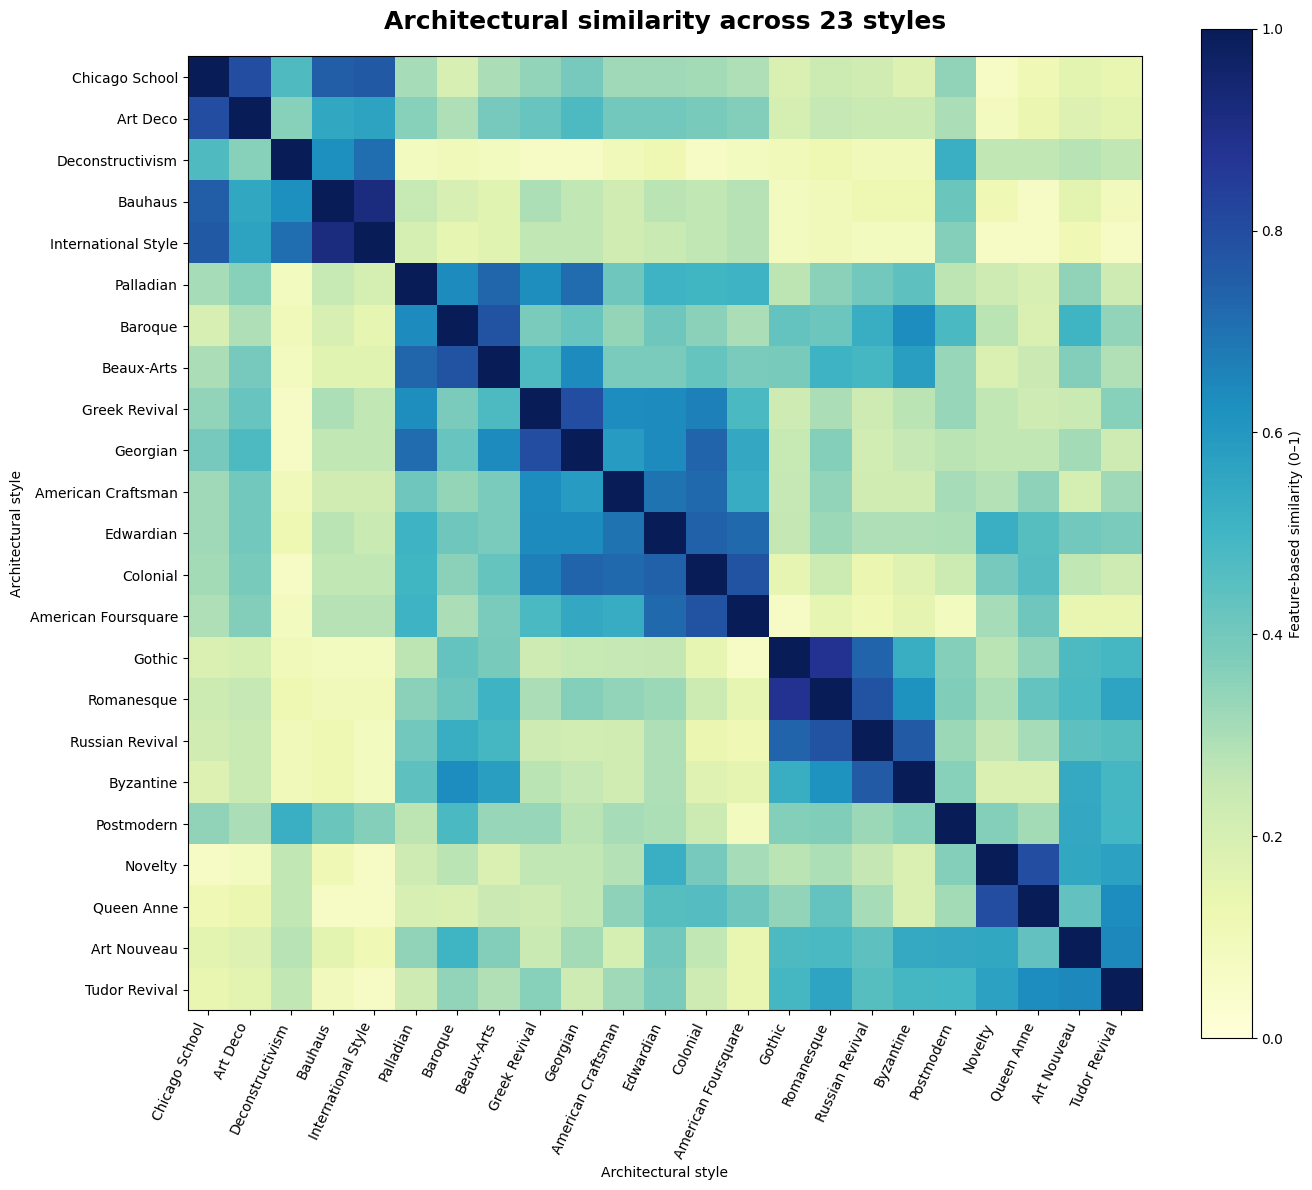

In [26]:
import matplotlib.pyplot as plt

# Original hierarchical ordering
style_order = [
    "Chicago School",
    "Art Deco",
    "Deconstructivism",
    "Bauhaus",
    "International Style",
    "Palladian",
    "Baroque",
    "Beaux-Arts",
    "Greek Revival",
    "Georgian",
    "American Craftsman",
    "Edwardian",
    "Colonial",
    "American Foursquare",
    "Gothic",
    "Romanesque",
    "Russian Revival",
    "Byzantine",
    "Postmodern",
    "Novelty",
    "Queen Anne",
    "Art Nouveau",
    "Tudor Revival"
]

# Reorder both rows and columns
M_ordered = M_feature.loc[style_order, style_order]

fig, ax = plt.subplots(figsize=(14, 12))

im = ax.imshow(
    M_ordered.values,
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

fig.colorbar(im, ax=ax, label="Feature-based similarity (0–1)")

ax.set_xticks(range(len(style_order)))
ax.set_yticks(range(len(style_order)))

ax.set_xticklabels(style_order, rotation=65, ha="right")
ax.set_yticklabels(style_order)

ax.set_xlabel("Architectural style")
ax.set_ylabel("Architectural style")
ax.set_title(
    "Architectural similarity across 23 styles",
    fontsize=18,
    fontweight="bold",
    pad=20
)

fig.tight_layout()

fig.savefig(
    "architectural_similarity_hierarchical.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 11. Global distribution of architectural similarity

With 23 styles there are

binom{23}{2}=253 unique cross-style pairs.

Because M_feature is symmetric, only the upper triangle is needed. The diagonal is excluded because self-similarity is trivially maximal.

The resulting distribution provides the background architectural landscape against which CLIP's cross-label retrievals will later be compared.

> **Key idea**  
> A CLIP mismatch score becomes much more interpretable when we know where it lies relative to *all possible cross-style relationships*.


In [27]:
import numpy as np
import pandas as pd

# Extract upper triangle, excluding diagonal
mask = np.triu(np.ones(M_feature.shape, dtype=bool), k=1)
sims = M_feature.where(mask).stack()

print("Number of style pairs:", len(sims))
print("\nSimilarity distribution:")
print(sims.describe().round(3))

print("\nPercentiles:")
print(
    sims.quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
    .round(3)
)

Number of style pairs: 253

Similarity distribution:
count    253.000
mean       0.345
std        0.193
min        0.060
25%        0.220
50%        0.307
75%        0.460
max        0.917
dtype: float64

Percentiles:
0.05    0.080
0.10    0.102
0.25    0.220
0.50    0.307
0.75    0.460
0.90    0.639
0.95    0.733
dtype: float64


### 12. Inspect the strongest architectural relationships

The unique pairwise similarities are converted into a tidy table and ranked.

This provides another face-validity check and identifies the relationships occupying the upper tail of the architectural space.

These values will later support percentile statements such as: *this CLIP mismatch falls within the top 10% of all architectural style relationships.*


In [28]:
#Convert unique pair similarities to a table
pairs = (
    sims.rename("similarity")
    .reset_index()
)

pairs.columns = ["style_1", "style_2", "similarity"]

print("TOP 15 MOST SIMILAR STYLE PAIRS")
display(
    pairs.sort_values("similarity", ascending=False)
         .head(15)
         .reset_index(drop=True)
         .round(3)
)

print("\nBOTTOM 15 LEAST SIMILAR STYLE PAIRS")
display(
    pairs.sort_values("similarity", ascending=True)
         .head(15)
         .reset_index(drop=True)
         .round(3)
)

TOP 15 MOST SIMILAR STYLE PAIRS


,style_1,style_2,similarity
0,Bauhaus,International Style,0.917
1,Gothic,Romanesque,0.880
2,Novelty,Queen Anne,0.800
3,Greek Revival,Georgian,0.800
4,Chicago School,Art Deco,0.800
5,Colonial,American Foursquare,0.780
6,Baroque,Beaux-Arts,0.780
7,Russian Revival,Romanesque,0.780
8,Chicago School,International Style,0.763
9,Russian Revival,Byzantine,0.760



BOTTOM 15 LEAST SIMILAR STYLE PAIRS


,style_1,style_2,similarity
0,Novelty,Chicago School,0.06
1,Deconstructivism,Greek Revival,0.06
2,Deconstructivism,Georgian,0.06
3,Novelty,International Style,0.06
4,Deconstructivism,Colonial,0.06
5,Gothic,American Foursquare,0.06
6,Queen Anne,International Style,0.06
7,Queen Anne,Bauhaus,0.06
8,Tudor Revival,International Style,0.06
9,Deconstructivism,American Foursquare,0.08


### 13. Create the CLIP vs Architectural Similarity Plot

Number of style pairs: 253
Spearman rho: 0.435
Permutation p-value: 4.999750012499375e-05


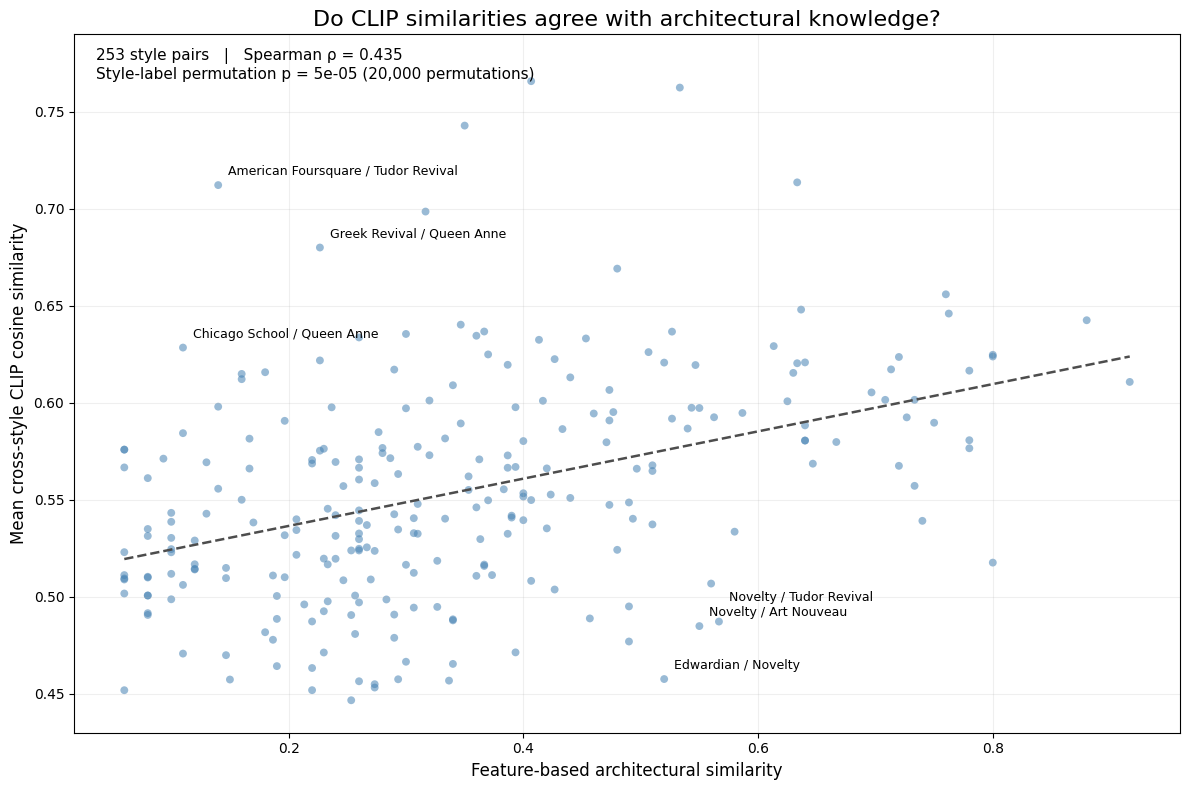

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ==================================================
# 1. Load CLIP embeddings and metadata
# ==================================================

embeddings = np.load("clip_image_embeddings.npy")
metadata = pd.read_csv("architecture_metadata.csv")

assert len(embeddings) == len(metadata)

excluded = [
    "Achaemenid architecture",
    "Ancient Egyptian architecture"
]

mask = ~metadata["style"].isin(excluded)

E = embeddings[mask.to_numpy()]
meta = metadata.loc[mask].reset_index(drop=True)

assert len(E) == 9315
assert meta["style"].nunique() == 23

# ==================================================
# 2. Match architectural style names
# ==================================================

style_map = {
    "American craftsman style": "American Craftsman",
    "Chicago school": "Chicago School",
    "International style": "International Style"
}

meta["style_clean"] = (
    meta["style"]
    .str.replace(" architecture", "", regex=False)
    .str.strip()
    .replace(style_map)
)

assert set(meta["style_clean"]) == set(M_feature.index)

# ==================================================
# 3. Calculate mean cross-style CLIP similarity
# ==================================================

# Normalize embeddings to unit length
E = E / np.linalg.norm(E, axis=1, keepdims=True)

styles = list(M_feature.index)
labels = meta["style_clean"].to_numpy()

style_means = {}

for style in styles:
    style_embeddings = E[labels == style]
    style_means[style] = style_embeddings.mean(axis=0)

results = pairs.copy()

results["clip_similarity"] = [
    float(style_means[a] @ style_means[b])
    for a, b in zip(
        results["style_1"],
        results["style_2"]
    )
]

x = results["similarity"].to_numpy()
y = results["clip_similarity"].to_numpy()

# ==================================================
# 4. Spearman correlation
# ==================================================

rho, _ = spearmanr(x, y)

print("Number of style pairs:", len(results))
print("Spearman rho:", round(rho, 3))

# ==================================================
# 5. Style-label permutation test
# ==================================================

rng = np.random.default_rng(42)
n_perm = 20000

C = np.array([
    [
        style_means[a] @ style_means[b]
        for b in styles
    ]
    for a in styles
])

A = M_feature.loc[styles, styles].to_numpy()

iu = np.triu_indices(len(styles), k=1)

observed_rho = spearmanr(A[iu], C[iu]).statistic

extreme = 0

for _ in range(n_perm):
    perm = rng.permutation(len(styles))

    permuted_C = C[np.ix_(perm, perm)]

    r = spearmanr(
        A[iu],
        permuted_C[iu]
    ).statistic

    if abs(r) >= abs(observed_rho):
        extreme += 1

p_value = (extreme + 1) / (n_perm + 1)

print("Permutation p-value:", p_value)

# ==================================================
# 6. Create scatterplot
# ==================================================

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    x,
    y,
    s=32,
    alpha=0.55,
    color="steelblue",
    edgecolors="none"
)

# Linear trend line
slope, intercept = np.polyfit(x, y, 1)

xx = np.linspace(x.min(), x.max(), 200)

ax.plot(
    xx,
    slope * xx + intercept,
    "--",
    color="0.3",
    linewidth=1.8
)

# ==================================================
# 7. Annotate selected outlying style pairs
# ==================================================

selected_pairs = [
    ("American Foursquare", "Tudor Revival"),
    ("Greek Revival", "Queen Anne"),
    ("Chicago School", "Queen Anne"),
    ("Novelty", "Art Nouveau"),
    ("Novelty", "Tudor Revival"),
    ("Edwardian", "Novelty")
]

# Individual offsets to reduce label overlap
label_offsets = {
    ("American Foursquare", "Tudor Revival"): (7, 7),
    ("Greek Revival", "Queen Anne"): (7, 7),
    ("Chicago School", "Queen Anne"): (7, 7),
    ("Novelty", "Art Nouveau"): (7, 7),
    ("Novelty", "Tudor Revival"): (7, 15),
    ("Edwardian", "Novelty"): (7, 7)
}

for a, b in selected_pairs:

    match = results[
        (
            (results["style_1"] == a) &
            (results["style_2"] == b)
        ) |
        (
            (results["style_1"] == b) &
            (results["style_2"] == a)
        )
    ]

    if len(match) == 1:

        row = match.iloc[0]

        dx, dy = label_offsets[(a, b)]

        ax.annotate(
            f"{a} / {b}",
            (
                row["similarity"],
                row["clip_similarity"]
            ),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=9
        )

# ==================================================
# 8. Labels, title, and statistics
# ==================================================

ax.set_xlabel(
    "Feature-based architectural similarity",
    fontsize=12
)

ax.set_ylabel(
    "Mean cross-style CLIP cosine similarity",
    fontsize=12
)

ax.set_title(
    "Do CLIP similarities agree with architectural knowledge?",
    fontsize=16
)

ax.text(
    0.02,
    0.98,
    f"253 style pairs   |   Spearman ρ = {rho:.3f}\n"
    f"Style-label permutation p = {p_value:.2g} "
    f"({n_perm:,} permutations)",
    transform=ax.transAxes,
    va="top",
    fontsize=11
)

# Extra vertical space for the highest points
ax.set_ylim(0.43, 0.79)

ax.grid(alpha=0.2)

plt.tight_layout()

# ==================================================
# 9. Save high-resolution figure
# ==================================================

plt.savefig(
    "clip_vs_architecture_similarity_annotated.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Part III · Join the independent architectural space to CLIP retrievals

## 14. Load the frozen CLIP top-1 results

The file `clip_top1_domain_results.csv` was generated previously from the 23-style CLIP retrieval experiment.

This ordering is methodologically important:

1. CLIP retrievals were generated first.
2. M_feature was constructed as an explicit architectural representation.
3. The two are joined only now for analysis.

Therefore the architectural score does not determine which image CLIP retrieves.


In [13]:
clip_top1 = pd.read_csv("clip_top1_domain_results.csv")

print("Number of CLIP retrievals:", len(clip_top1))
display(clip_top1.head())

Number of CLIP retrievals: 9315


,query_id,query_style,retrieved_id,retrieved_style,clip_similarity
0,0,American Foursquare architecture,7514,Queen Anne architecture,0.723876
1,1,American Foursquare architecture,340,American Foursquare architecture,0.987062
2,2,American Foursquare architecture,7880,Queen Anne architecture,0.902493
3,3,American Foursquare architecture,7516,Queen Anne architecture,0.879560
4,4,American Foursquare architecture,5141,Georgian architecture,0.924064


### 15. Normalize style names before joining the two representations

The CLIP metadata and M_feature use slightly different naming conventions—for example, some dataset labels contain the word *architecture*.

These strings must be normalized before lookup.

This step changes **names only**. It does not merge architectural categories, alter retrievals, or change similarity values.


In [14]:
# Make a clean copy
clip_top1 = clip_top1.copy()

# Create normalized style-name columns
clip_top1["query_style_clean"] = (
    clip_top1["query_style"]
    .astype(str)
    .str.replace(" architecture", "", regex=False)
    .str.strip()
)

clip_top1["retrieved_style_clean"] = (
    clip_top1["retrieved_style"]
    .astype(str)
    .str.replace(" architecture", "", regex=False)
    .str.strip()
)

# Verify the new columns exist
print(clip_top1.columns.tolist())

display(
    clip_top1[
        ["query_style", "query_style_clean",
         "retrieved_style", "retrieved_style_clean"]
    ].head()
)

['query_id', 'query_style', 'retrieved_id', 'retrieved_style', 'clip_similarity', 'query_style_clean', 'retrieved_style_clean']


,query_style,query_style_clean,retrieved_style,retrieved_style_clean
0,American Foursquare architecture,American Foursquare,Queen Anne architecture,Queen Anne
1,American Foursquare architecture,American Foursquare,American Foursquare architecture,American Foursquare
2,American Foursquare architecture,American Foursquare,Queen Anne architecture,Queen Anne
3,American Foursquare architecture,American Foursquare,Queen Anne architecture,Queen Anne
4,American Foursquare architecture,American Foursquare,Georgian architecture,Georgian


### 16. Verify style-vocabulary compatibility

Before attaching architectural scores, we compare the set of CLIP style names with the index of M_feature.

A failed vocabulary match could create missing lookups or, worse, silently misalign categories.

This explicit check is therefore a data-integrity gate before the central analysis.


In [15]:
clip_styles = set(clip_top1["query_style_clean"].unique())
feature_styles = set(M_feature.index)

print("Number of CLIP styles:", len(clip_styles))
print("Number of M_feature styles:", len(feature_styles))

print("\nIn CLIP but NOT in M_feature:")
print(sorted(clip_styles - feature_styles))

print("\nIn M_feature but NOT in CLIP:")
print(sorted(feature_styles - clip_styles))

Number of CLIP styles: 23
Number of M_feature styles: 23

In CLIP but NOT in M_feature:
['American craftsman style', 'Chicago school', 'International style']

In M_feature but NOT in CLIP:
['American Craftsman', 'Chicago School', 'International Style']


### 17. Resolve the remaining naming variants

A small mapping harmonizes residual capitalization/wording differences such as *Chicago school* versus *Chicago School*.

Again, these are aliases for the same categories—not substantive recoding.

After this cell, the CLIP retrieval table and architectural matrix should refer to exactly the same 23 style names.


In [16]:
style_name_map = {
    "American craftsman style": "American Craftsman",
    "Chicago school": "Chicago School",
    "International style": "International Style"
}

clip_top1["query_style_clean"] = (
    clip_top1["query_style_clean"]
    .replace(style_name_map)
)

clip_top1["retrieved_style_clean"] = (
    clip_top1["retrieved_style_clean"]
    .replace(style_name_map)
)

# Verify again
clip_styles = set(clip_top1["query_style_clean"].unique())
feature_styles = set(M_feature.index)

print("Number of CLIP styles:", len(clip_styles))
print("Number of M_feature styles:", len(feature_styles))

print("\nIn CLIP but NOT in M_feature:")
print(sorted(clip_styles - feature_styles))

print("\nIn M_feature but NOT in CLIP:")
print(sorted(feature_styles - clip_styles))

Number of CLIP styles: 23
Number of M_feature styles: 23

In CLIP but NOT in M_feature:
[]

In M_feature but NOT in CLIP:
[]


### 18. Attach graded architectural relevance to every CLIP top-1 retrieval

For an exact label match, architectural similarity is assigned 1.0.

For a cross-label retrieval, the score is read from

M_feature(query_style,retrieved_style).

This creates two parallel views of each retrieval:

| Evaluation view | Question |
|---|---|
| **Exact-label** | Are the two dataset style labels identical? |
| **Graded architectural** | How similar are the two style categories architecturally? |

> **Crucial distinction**  
> `clip_similarity` is image-level similarity learned by CLIP.  
> `architectural_similarity` is style-level similarity from our independent architectural representation.


In [17]:
# Exact dataset-label match
clip_top1["label_match"] = (
    clip_top1["query_style_clean"]
    == clip_top1["retrieved_style_clean"]
)

# Architectural similarity of each CLIP top-1 result
def get_architectural_similarity(row):
    if row["label_match"]:
        return 1.0

    return M_feature.loc[
        row["query_style_clean"],
        row["retrieved_style_clean"]
    ]

clip_top1["architectural_similarity"] = clip_top1.apply(
    get_architectural_similarity,
    axis=1
)

display(
    clip_top1[
        [
            "query_style_clean",
            "retrieved_style_clean",
            "clip_similarity",
            "label_match",
            "architectural_similarity"
        ]
    ].head(10)
)

,query_style_clean,retrieved_style_clean,clip_similarity,label_match,architectural_similarity
0,American Foursquare,Queen Anne,0.723876,False,0.406667
1,American Foursquare,American Foursquare,0.987062,True,1.000000
2,American Foursquare,Queen Anne,0.902493,False,0.406667
3,American Foursquare,Queen Anne,0.879560,False,0.406667
4,American Foursquare,Georgian,0.924064,False,0.546667
5,American Foursquare,Queen Anne,0.930596,False,0.406667
6,American Foursquare,Queen Anne,0.920082,False,0.406667
7,American Foursquare,American Craftsman,1.000000,False,0.533333
8,American Foursquare,American Foursquare,0.923566,True,1.000000
9,American Foursquare,American Foursquare,0.917539,True,1.000000


## Part IV · Test whether CLIP's “errors” contain architectural structure

### 19. Isolate exact-label mismatches

Conventional P@1 evaluation calls every different-label top-1 retrieval wrong.

We isolate precisely that population and ask a different question:

> **Among the retrievals that fail exact-label evaluation, how architecturally similar are the query and retrieved styles?**

This does not change P@1. It investigates what the binary metric leaves unmeasured.


In [18]:
# CLIP top-1 results that conventional label evaluation calls "wrong"
mismatches = clip_top1[~clip_top1["label_match"]].copy()

print("Total queries:", len(clip_top1))
print("Exact-label matches:", clip_top1["label_match"].sum())
print("Label mismatches:", len(mismatches))

print(
    "\nExact-label P@1:",
    round(clip_top1["label_match"].mean(), 4)
)

print("\nArchitectural similarity among label mismatches:")
print(
    mismatches["architectural_similarity"]
    .describe()
    .round(3)
)

print("\nPercentiles:")
print(
    mismatches["architectural_similarity"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90])
    .round(3)
)

Total queries: 9315
Exact-label matches: 6850
Label mismatches: 2465

Exact-label P@1: 0.7354

Architectural similarity among label mismatches:
count    2465.000
mean        0.500
std         0.213
min         0.060
25%         0.350
50%         0.473
75%         0.667
max         0.917
Name: architectural_similarity, dtype: float64

Percentiles:
0.10    0.227
0.25    0.350
0.50    0.473
0.75    0.667
0.90    0.800
Name: architectural_similarity, dtype: float64


### 20. Convert mismatch similarity into percentile rank

Raw architectural similarity is useful, but percentile rank gives it a natural reference frame.

For each CLIP mismatch, we ask:

> What percentage of all 253 possible cross-style architectural relationships have similarity less than or equal to this one?

A percentile near 90 means that the retrieved style is more architecturally related to the query than roughly 90% of all possible different-style pairings.

This lets us test whether CLIP mismatches are disproportionately concentrated in the upper tail of the independent architectural space.


In [19]:
# Percentile rank of each CLIP label mismatch
# relative to all possible cross-style architectural similarities

background = sims.to_numpy()

def similarity_percentile(x):
    return 100 * np.mean(background <= x)

mismatches["arch_similarity_percentile"] = (
    mismatches["architectural_similarity"]
    .apply(similarity_percentile)
)

print("Percentile rank of CLIP mismatches")
print(
    mismatches["arch_similarity_percentile"]
    .describe()
    .round(1)
)

print("\nFraction of CLIP mismatches in:")
print(
    "Top 25% of architectural relationships:",
    round((mismatches["arch_similarity_percentile"] >= 75).mean(), 3)
)

print(
    "Top 10% of architectural relationships:",
    round((mismatches["arch_similarity_percentile"] >= 90).mean(), 3)
)

print(
    "Top 5% of architectural relationships:",
    round((mismatches["arch_similarity_percentile"] >= 95).mean(), 3)
)

Percentile rank of CLIP mismatches
count    2465.0
mean       71.2
std        24.5
min         3.6
25%        58.1
50%        76.7
75%        92.1
max       100.0
Name: arch_similarity_percentile, dtype: float64

Fraction of CLIP mismatches in:
Top 25% of architectural relationships: 0.514
Top 10% of architectural relationships: 0.275
Top 5% of architectural relationships: 0.186


### 21. Build a frequency-aware random baseline

A naïve random baseline would treat all styles as equally likely retrievals. The dataset, however, contains unequal numbers of images per style.

The null model therefore preserves the **empirical style-frequency structure**.

For each mismatch query style, we ask what architectural similarity would be expected if a different style were selected randomly in proportion to its availability in the dataset.

> **Null hypothesis**  
> CLIP's cross-label retrievals are no more architecturally related to their queries than frequency-aware random different-style retrievals.

This is a substantially stronger comparison than simply contrasting CLIP against a uniform random style choice.


In [20]:
# ================================================================
# NULL BASELINE: EXPECTED ARCHITECTURAL SIMILARITY BY RANDOM CHANCE
# ================================================================
#
# PURPOSE
# -------
# We previously found that CLIP's top-1 retrieval has a different
# architectural-style label for 2,465 of the 9,315 query images.
#
# Importantly, those CLIP "label mismatches" are not necessarily
# architecturally bad retrievals. Their mean architectural similarity
# according to M_feature is 0.500.
#
# We now need to determine whether 0.500 is genuinely meaningful.
#
# QUESTION
# --------
# When CLIP retrieves an image with the wrong style label, does it
# tend to retrieve an ARCHITECTURALLY RELATED style more often than
# we would expect from random retrieval?
#
# WHY A FREQUENCY-AWARE RANDOM BASELINE?
# --------------------------------------
# The 23 architectural styles may contain different numbers of images.
# Therefore, randomly selecting one of the other 22 STYLE LABELS with
# equal probability would not accurately represent random retrieval
# from the actual image dataset.
#
# Instead, for each query style:
#
#   1. Exclude images having the same style as the query.
#   2. Use the actual number of images belonging to each remaining
#      style to determine its probability of being randomly retrieved.
#   3. Weight the M_feature architectural similarity by those
#      probabilities.
#
# This gives the expected architectural similarity if retrieval were
# random while preserving the real style-frequency distribution.
#
# INTERPRETATION
# --------------
# We will compare:
#
#   observed CLIP mismatch similarity
#
#                 versus
#
#   expected similarity under random retrieval
#
# If CLIP's value is substantially larger, this suggests that CLIP's
# apparent label errors are NOT random with respect to architecture.
# Instead, CLIP tends to retrieve styles that are architecturally
# related to the query style.
# ================================================================


# Count how many query images belong to each of the 23 styles.
# These counts define the empirical style frequencies in the dataset.
style_counts = (
    clip_top1["query_style_clean"]
    .value_counts()
)


# Store the expected random architectural similarity for each
# of CLIP's 2,465 different-label retrieval cases.
random_expected = []


for _, row in mismatches.iterrows():

    query_style = row["query_style_clean"]

    # Remove the query's own style.
    #
    # We are specifically analyzing DIFFERENT-LABEL retrievals, so
    # the random baseline must also be restricted to different styles.
    candidate_counts = style_counts.drop(query_style)

    # Convert image counts into retrieval probabilities.
    #
    # A style containing more images has a greater probability of
    # being selected by random image retrieval.
    probabilities = (
        candidate_counts / candidate_counts.sum()
    )

    # Compute the expected M_feature architectural similarity.
    #
    # For every possible different style:
    #
    #   probability of randomly retrieving that style
    #                       ×
    #   architectural similarity to the query style
    #
    # Summing these values gives the expected similarity under
    # frequency-aware random retrieval.
    expected_similarity = sum(
        probabilities[style]
        * M_feature.loc[query_style, style]
        for style in candidate_counts.index
    )

    random_expected.append(expected_similarity)


# Attach the random expectation to each CLIP mismatch so that later
# analyses can compare observed CLIP similarity with its corresponding
# random expectation.
mismatches["random_expected_similarity"] = random_expected


# ------------------------------------------------
# SUMMARY COMPARISON
# ------------------------------------------------

print("CLIP mismatches:")
print(
    "Mean architectural similarity:",
    round(
        mismatches["architectural_similarity"].mean(),
        3
    )
)

print("\nFrequency-aware random baseline:")
print(
    "Mean expected architectural similarity:",
    round(
        mismatches["random_expected_similarity"].mean(),
        3
    )
)

print("\nCLIP advantage over random retrieval:")
print(
    round(
        mismatches["architectural_similarity"].mean()
        - mismatches["random_expected_similarity"].mean(),
        3
    )
)

CLIP mismatches:
Mean architectural similarity: 0.5

Frequency-aware random baseline:
Mean expected architectural similarity: 0.35

CLIP advantage over random retrieval:
0.15


### 22. Monte Carlo test of the null hypothesis

The analytical baseline gives the expected random similarity. The Monte Carlo experiment asks how much random variation we should expect around that value.

Across many simulated trials, each mismatch query receives a random different-style retrieval under the same frequency-aware null model. For every trial we compute the mean architectural similarity.

The observed CLIP mismatch mean is then compared with that distribution.

> **Interpretation rule**  
> If the observed CLIP mean lies far beyond the simulated null distribution, the enrichment cannot plausibly be explained merely by dataset style frequencies.


In [21]:
# =====================================================================
# VECTORIZED MONTE CARLO NULL TEST
# =====================================================================
#
# PURPOSE
# -------
# We want to test whether CLIP's DIFFERENT-LABEL retrievals are more
# architecturally related to the query than would occur by chance.
#
# We already observed:
#
#   CLIP mismatch mean architectural similarity = 0.500
#   Frequency-aware random expectation          = 0.350
#
# The analytical expectation of 0.350 tells us where random retrieval
# should be centered. The Monte Carlo experiment now tells us how much
# RANDOM VARIATION exists around that value.
#
#
# NULL HYPOTHESIS
# ---------------
# CLIP's different-label retrievals contain no special architectural
# structure. Any architectural similarity we observe could have arisen
# from random retrieval of images belonging to different styles.
#
#
# SIMULATION DESIGN
# -----------------
# We reproduce the 2,465 actual mismatch queries.
#
# For each query, random retrieval is allowed to select any OTHER
# architectural style, with probability proportional to the number
# of images of that style in the actual dataset.
#
# We repeat the complete random experiment 10,000 times.
#
# This produces 10,000 random mean architectural-similarity values:
#
#       null_means[0], null_means[1], ..., null_means[9999]
#
# These values form the empirical NULL DISTRIBUTION against which
# CLIP's observed mean of approximately 0.500 will be compared.
#
#
# WHY THIS VERSION IS FAST
# ------------------------
# The previous implementation performed millions of operations inside
# nested Python loops and repeatedly accessed pandas objects.
#
# Here we first convert the relevant information into NumPy arrays.
# Random retrievals are then generated in large vectorized blocks.
#
# The scientific experiment is the same; only the implementation is
# computationally more efficient.
# =====================================================================


import numpy as np


# Reproducible random-number generator.
rng = np.random.default_rng(42)

n_trials = 10_000


# ---------------------------------------------------------------------
# STEP 1: CREATE A FIXED ORDER FOR THE 23 ARCHITECTURAL STYLES
# ---------------------------------------------------------------------

styles = np.array(M_feature.index)

style_to_idx = {
    style: i
    for i, style in enumerate(styles)
}


# Convert M_feature from a pandas DataFrame into a NumPy matrix.
#
# Entry [i, j] contains the architectural similarity between
# style i and style j.
M = M_feature.loc[styles, styles].to_numpy()


# Number of images belonging to each architectural style.
counts = np.array(
    [style_counts[style] for style in styles],
    dtype=float
)


# ---------------------------------------------------------------------
# STEP 2: GROUP THE 2,465 MISMATCH QUERIES BY QUERY STYLE
# ---------------------------------------------------------------------
#
# Many mismatch cases have the same query style. We therefore do not
# need to process all 2,465 queries individually inside every trial.
#
# Instead, for each query style we determine how many mismatch cases
# came from that style.

mismatch_counts = (
    mismatches["query_style_clean"]
    .value_counts()
    .reindex(styles, fill_value=0)
    .to_numpy()
)


# ---------------------------------------------------------------------
# STEP 3: RUN 10,000 FREQUENCY-AWARE RANDOM RETRIEVAL EXPERIMENTS
# ---------------------------------------------------------------------

# Each element will eventually contain the TOTAL architectural
# similarity accumulated across all 2,465 simulated retrievals
# for one Monte Carlo trial.
null_totals = np.zeros(n_trials)

total_mismatches = mismatch_counts.sum()


for query_idx, n_queries in enumerate(mismatch_counts):

    # Some styles might contribute no CLIP mismatches.
    if n_queries == 0:
        continue

    # Start with the actual dataset frequencies.
    probabilities = counts.copy()

    # Random retrieval must have a DIFFERENT style label, because
    # we are constructing a null model specifically for CLIP's
    # different-label retrieval cases.
    probabilities[query_idx] = 0

    probabilities /= probabilities.sum()


    # Rather than simulate each query separately, generate the number
    # of random retrievals assigned to each possible style.
    #
    # Shape:
    #
    #       (10,000 trials, 23 retrieved styles)
    #
    # Each row represents one complete random experiment for all
    # mismatch queries belonging to this particular query style.
    random_counts = rng.multinomial(
        n_queries,
        probabilities,
        size=n_trials
    )


    # Architectural similarity between this query style and all
    # possible retrieved styles.
    similarities = M[query_idx]


    # Matrix multiplication gives the total architectural similarity
    # contributed by this query style in every Monte Carlo trial.
    null_totals += random_counts @ similarities


# Convert accumulated totals into mean architectural similarity
# across all 2,465 simulated mismatch retrievals.
null_means = null_totals / total_mismatches


# ---------------------------------------------------------------------
# STEP 4: COMPARE RANDOM RETRIEVAL WITH THE ACTUAL CLIP RESULT
# ---------------------------------------------------------------------

clip_observed_mean = (
    mismatches["architectural_similarity"].mean()
)

null_mean = null_means.mean()
null_std = null_means.std()


# Monte Carlo p-value:
#
# How often did random retrieval produce a mean architectural
# similarity at least as large as the actual CLIP result?
#
# The +1 correction prevents us from reporting p = 0 simply because
# none of the 10,000 simulated experiments reached CLIP's value.
p_value = (
    (np.sum(null_means >= clip_observed_mean) + 1)
    / (n_trials + 1)
)


# ---------------------------------------------------------------------
# RESULTS
# ---------------------------------------------------------------------

print("Number of CLIP mismatch queries:")
print(total_mismatches)

print("\nObserved CLIP mismatch mean:")
print(round(clip_observed_mean, 4))

print("\nMonte Carlo null distribution:")
print("Mean:", round(null_mean, 4))
print("Standard deviation:", round(null_std, 4))

print("\n95% range of random-trial means:")
print(
    np.round(
        np.percentile(null_means, [2.5, 97.5]),
        4
    )
)

print("\nLargest mean produced by any random trial:")
print(round(null_means.max(), 4))

print("\nMonte Carlo p-value:")
print(p_value)

Number of CLIP mismatch queries:
2465

Observed CLIP mismatch mean:
0.5001

Monte Carlo null distribution:
Mean: 0.35
Standard deviation: 0.0037

95% range of random-trial means:
[0.3429 0.3573]

Largest mean produced by any random trial:
0.3638

Monte Carlo p-value:
9.999000099990002e-05


## Part V · Check whether the effect is broad or driven by a few pairs

### 23. Which directional style pairs does CLIP retrieve most often?

Statistical significance alone is not enough. A strong overall result could conceivably be produced by a small number of repeated style pairings.

Note direction matters for retrieval frequency. 

For each pair we examine its frequency, mean CLIP similarity, architectural similarity, and share of all mismatches.


In [22]:
# =====================================================================
# WHICH CROSS-LABEL STYLE PAIRS ARE CLIP RETRIEVING MOST OFTEN?
# =====================================================================
#
# PURPOSE
# -------
# The Monte Carlo experiment showed that CLIP's 2,465 different-label
# retrievals have substantially greater architectural similarity than
# expected under frequency-aware random retrieval:
#
#       CLIP observed mean = 0.5001
#       Random null mean   = 0.3500
#
# None of 10,000 random trials approached the CLIP result.
#
# We now want to understand WHERE this effect comes from.
#
#
# RESEARCH QUESTION
# -----------------
# Is CLIP's architectural advantage:
#
#   A) broadly distributed across many different architectural
#      style relationships,
#
# or
#
#   B) dominated by only a few very common, highly similar pairs
#      such as Bauhaus <-> International Style?
#
#
# WHAT THIS CELL DOES
# -------------------
# We group all 2,465 CLIP label mismatches according to:
#
#       query style -> retrieved style
#
# For each directional style pair, we calculate:
#
#   1. Number of times CLIP made that particular retrieval.
#
#   2. Percentage of all 2,465 mismatches represented by that pair.
#
#   3. CLIP's mean image-level embedding similarity for those cases.
#
#   4. The M_feature architectural similarity between the two styles.
#
#
# IMPORTANT DISTINCTION
# ---------------------
# These pairs are DIRECTIONAL.
#
#       Gothic -> Romanesque
#
# and
#
#       Romanesque -> Gothic
#
# are counted separately because CLIP retrieval itself is directional,
# even though M_feature is symmetric.
#
#
# WHY THIS MATTERS
# ----------------
# If many frequently occurring mismatch pairs have reasonably high
# M_feature similarity, that supports the interpretation that CLIP's
# cross-label architectural structure is broad.
#
# If nearly all of the effect comes from only one or two style pairs,
# we would need to make a much narrower claim in the paper.
#
# This is therefore a diagnostic of how GENERAL the architectural
# structure discovered in CLIP's mismatch behavior appears to be.
# =====================================================================


# Group the different-label CLIP retrievals by directional style pair.
pair_summary = (
    mismatches
    .groupby(
        ["query_style_clean", "retrieved_style_clean"],
        as_index=False
    )
    .agg(
        retrieval_count=("query_id", "count"),
        mean_clip_similarity=("clip_similarity", "mean"),
        architectural_similarity=("architectural_similarity", "first")
    )
)


# Calculate how much each directional pair contributes to the entire
# set of 2,465 CLIP label mismatches.
pair_summary["percent_of_all_mismatches"] = (
    100
    * pair_summary["retrieval_count"]
    / len(mismatches)
)


# Sort by frequency so that the style relationships CLIP confuses
# most often appear first.
pair_summary = (
    pair_summary
    .sort_values(
        "retrieval_count",
        ascending=False
    )
    .reset_index(drop=True)
)


# Make the output easier to read.
pair_summary["mean_clip_similarity"] = (
    pair_summary["mean_clip_similarity"].round(3)
)

pair_summary["architectural_similarity"] = (
    pair_summary["architectural_similarity"].round(3)
)

pair_summary["percent_of_all_mismatches"] = (
    pair_summary["percent_of_all_mismatches"].round(2)
)


print("Number of distinct directional mismatch pairs:")
print(len(pair_summary))

print("\nTop 25 most frequent CLIP cross-label retrieval pairs:")

display(
    pair_summary.head(25)
)

Number of distinct directional mismatch pairs:
287

Top 25 most frequent CLIP cross-label retrieval pairs:


,query_style_clean,retrieved_style_clean,retrieval_count,mean_clip_similarity,architectural_similarity,percent_of_all_mismatches
0,American Foursquare,Queen Anne,68,0.906,0.407,2.76
1,International Style,Bauhaus,60,0.885,0.917,2.43
2,Bauhaus,International Style,57,0.894,0.917,2.31
3,Postmodern,International Style,56,0.875,0.367,2.27
4,American Foursquare,American Craftsman,52,0.914,0.533,2.11
5,American Craftsman,Queen Anne,52,0.917,0.350,2.11
6,Queen Anne,American Craftsman,48,0.915,0.350,1.95
7,Russian Revival,Byzantine,37,0.932,0.760,1.50
8,Tudor Revival,American Craftsman,37,0.909,0.317,1.50
9,Palladian,Georgian,36,0.913,0.713,1.46


### 24. Final concentration diagnostic

The last test asks how much of the mismatch population is accounted for by the most frequent directional style pairs.

We examine cumulative concentration among the top 5, 10, 25, and 50 pairs.

> **Why this is the final diagnostic**  
> If the architectural-enrichment result is spread across many relationships rather than dominated by a handful of pairs, our paper's finding is broader and more convincing.



In [23]:
# =====================================================================
# FINAL DIAGNOSTIC: ARE CLIP'S MISMATCHES CONCENTRATED IN A FEW PAIRS?
# =====================================================================
#
# PURPOSE
# -------
# We found 287 distinct directional style-pair mismatches.
#
# The most frequent individual pair accounts for only 2.76% of all
# 2,465 CLIP label mismatches, suggesting that the cross-label behavior
# is not dominated by one architectural relationship.
#
# This final diagnostic quantifies that observation.
#
#
# QUESTION
# --------
# What percentage of ALL CLIP mismatches is accounted for by the:
#
#       5 most frequent style pairs?
#      10 most frequent style pairs?
#      25 most frequent style pairs?
#      50 most frequent style pairs?
#
#
# INTERPRETATION
# --------------
# If a very small number of pairs accounted for most mismatches, our
# aggregate architectural-similarity result could potentially be driven
# by only a few unusually common architectural relationships.
#
# If the mismatches remain distributed across many pairs, that supports
# the interpretation that CLIP's cross-label behavior is relatively
# broad rather than being an artifact of one or two dominant pairs.
#
# This is intended as a descriptive concentration check, NOT as another
# statistical significance test.
# =====================================================================


total_mismatches = len(mismatches)

for n in [5, 10, 25, 50]:

    n_retrievals = (
        pair_summary
        .head(n)["retrieval_count"]
        .sum()
    )

    percentage = (
        100 * n_retrievals / total_mismatches
    )

    print(
        f"Top {n:>2} mismatch pairs: "
        f"{n_retrievals:>4} retrievals "
        f"({percentage:.1f}% of all mismatches)"
    )


print("\nTotal distinct directional mismatch pairs:")
print(len(pair_summary))

Top  5 mismatch pairs:  293 retrievals (11.9% of all mismatches)
Top 10 mismatch pairs:  503 retrievals (20.4% of all mismatches)
Top 25 mismatch pairs:  952 retrievals (38.6% of all mismatches)
Top 50 mismatch pairs: 1439 retrievals (58.4% of all mismatches)

Total distinct directional mismatch pairs:
287


---

# Paper takeaway

This notebook replaces the overly rigid idea that every cross-label retrieval is equally irrelevant with a **graded, independently constructed architectural relevance measure**.


The central finding supported by this workflow is that **exact style-label disagreement can substantially understate the architectural relevance present in CLIP retrievals**.

CLIP's cross-label nearest neighbors can be evaluated against an architectural feature space that was not used to generate those retrievals. The frequency-aware null model and Monte Carlo test then determine whether the observed architectural enrichment exceeds what would be expected by chance.

Finally, the directional-pair analysis checks that the effect is not merely an artifact of a few dominant confusions.
